# What Can Electrical Circuits Teach Us About Earthquake Engineering?

Change period and damping to explore an RLC circuit's mechanical counterpart.
[Setup and commands](README.md).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fmpy import simulate_fmu
from notebook_utils import GRAVITY, load_record, pseudo_acceleration

FMU = Path("fmu/SdofSpectrum.fmu")
RECORD_IDS = {"Northridge1994": 3, "Kobe1995": 4}
periods = np.array([0.3, 1.0, 2.0])
damping = 0.02

def peaks(record, periods=periods, damping=damping):
    """Return peak displacement in mm using the Modelica input correction."""
    accel, dt = load_record(record)
    sa = pseudo_acceleration(accel, dt, periods, damping, correction_time=5.0)
    return 1000 * sa * GRAVITY * (periods / (2 * np.pi)) ** 2

table = pd.DataFrame(
    {name: peaks(name) for name in ["Northridge1994", "Kobe1995"]},
    index=pd.Index(periods, name="Period [s]"),
)
table.round(1)

,Northridge1994,Kobe1995
Period [s],,
0.3,22.6,34.7
1.0,344.3,88.0
2.0,173.6,176.2


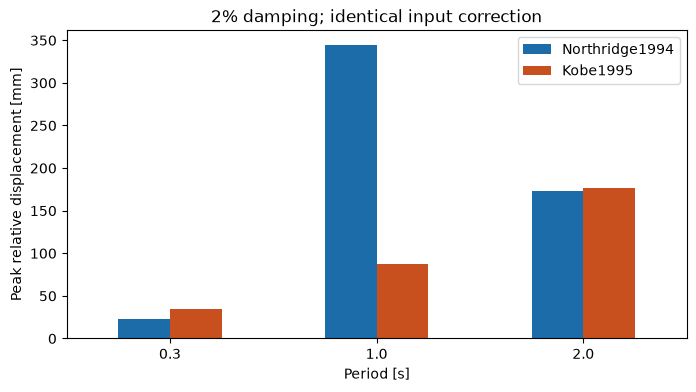

In [2]:
table.plot.bar(rot=0, color=["#1b6ca8", "#c8501e"], figsize=(8, 4))
plt.ylabel("Peak relative displacement [mm]")
plt.title("2% damping; identical input correction")
plt.show()

## Change period or damping

Sway modes, rather than storey counts, determine these model periods.

In [3]:
changed_periods = np.array([0.3, 1.0, 3.0])
pd.Series(peaks("Kobe1995", changed_periods, damping=0.05),
          index=changed_periods, name="Peak displacement [mm]").round(1)

0.3     28.7
1.0     75.7
3.0    178.1
Name: Peak displacement [mm], dtype: float64

## Check the FMU

CVODE uses adaptive implicit BDF. Tighten tolerance and sampling after changes.
Both solvers use identical input correction and free-response tails.

In [4]:
record = "Kobe1995"
accel, dt = load_record(record)
outputs = [f"relativeDisplacement[{i}]" for i in (2, 3, 4)]
result = simulate_fmu(
    FMU, start_values={"recordName": RECORD_IDS[record]},
    stop_time=(len(accel) - 1) * dt + 5 * max(periods),
    fmi_type="ModelExchange", solver="CVode", relative_tolerance=1e-7,
    output_interval=1e-3, output=outputs,
)
fmu_peaks = np.array([1000 * np.max(np.abs(result[name])) for name in outputs])
pd.DataFrame({"SciPy [mm]": peaks(record), "FMU [mm]": fmu_peaks,
              "Difference [%]": 100 * (fmu_peaks / peaks(record) - 1)},
             index=periods).round(3)

,SciPy [mm],FMU [mm],Difference [%]
0.3,34.685,34.795,0.315
1.0,87.998,87.999,0.001
2.0,176.207,176.238,0.017


## Inspect the ensemble

44 components, 22 station pairs, 14 earthquakes; 5% damping and PGA normalization.
Source processing is retained. The percentile band describes collection spread.

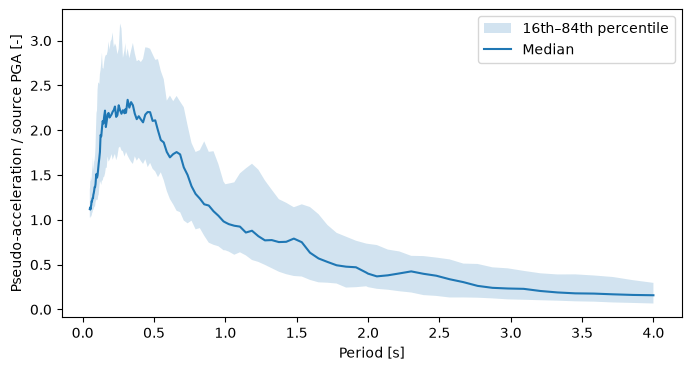

{'plateau': 2.5805948271396337, 'corner': 0.6021354961510884}

In [5]:
records = pd.read_csv("data/fema_p695_records.csv")
ensemble = pd.read_csv("data/fema_p695_normalized_spectra.csv")
low, median, high = np.percentile(ensemble.iloc[:, 1:].to_numpy(), [16, 50, 84], axis=1)
plt.figure(figsize=(8, 4))
plt.fill_between(ensemble.period_s, low, high, alpha=0.2, label="16th–84th percentile")
plt.plot(ensemble.period_s, median, label="Median")
plt.xlabel("Period [s]")
plt.ylabel("Pseudo-acceleration / source PGA [-]")
plt.legend()
plt.show()
from notebook_utils import fit_design_spectrum

fit_design_spectrum(ensemble.iloc[:, 1:].to_numpy().T)

## Inspect the frame

Elastic frame, nonlinear bearing. Roof deformation is relative to the frame base;
bearing travel is relative to ground. Their peaks need not coincide.

In [6]:
import json


def frame_peaks(record):
    p = json.load(open(f"data/{record}_frame_summary.json"))["peaks"]  # noqa: SIM115
    return {
        "Fixed roof [mm]": 1000 * p["fixedRoofDisplacement"],
        "Isolated roof [mm]": 1000 * p["isolatedRoofDisplacement"],
        "Bearing travel [mm]": 1000 * p["isolationTravel"],
        "Fixed stress ratio": p["fixedStressRatio"],
        "Isolated stress ratio": p["isolatedStressRatio"],
        "Fixed drift [%]": 100 * p["fixedMaxDriftRatio"],
        "Isolated drift [%]": 100 * p["isolatedMaxDriftRatio"],
    }

pd.DataFrame({name: frame_peaks(name) for name in RECORD_IDS}).round(2)

,Northridge1994,Kobe1995
Fixed roof [mm],429.61,114.09
Isolated roof [mm],60.86,54.28
Bearing travel [mm],227.06,108.59
Fixed stress ratio,2.36,0.76
Isolated stress ratio,0.37,0.29
Fixed drift [%],1.83,0.50
Isolated drift [%],0.27,0.25


## Cross-check with a shear-chain FMU

`TenStoreyShear.fmu` replaces the multibody frame with ten floor masses on equal
spring-damper storeys, sized to the same 1.05 s first period. It runs in seconds in any FMI 2.0
runner. Peaks stay within about 12% of the frame, except isolated roof drift, which is within 24%.

In [7]:
SHEAR = Path("fmu/TenStoreyShear.fmu")
OUTPUTS = ["fixedRoofDisplacement", "isolatedRoofDisplacement", "isolationTravel"]


def shear_peaks(record):
    result = simulate_fmu(
        SHEAR, start_values={"recordName": RECORD_IDS[record]}, stop_time=60,
        fmi_type="ModelExchange", solver="CVode", relative_tolerance=1e-6,
        output_interval=0.01, output=OUTPUTS,
    )
    return {name: 1000 * np.abs(result[name]).max() for name in OUTPUTS}


names = {"fixedRoofDisplacement": "Fixed roof [mm]",
         "isolatedRoofDisplacement": "Isolated roof [mm]",
         "isolationTravel": "Bearing travel [mm]"}
frame = pd.DataFrame({r: frame_peaks(r) for r in RECORD_IDS}).loc[list(names.values())]
shear = pd.DataFrame({r: shear_peaks(r) for r in RECORD_IDS}).rename(index=names)
(100 * (shear / frame - 1)).astype(float).round(1).add_suffix(" shear vs frame [%]")

,Northridge1994 shear vs frame [%],Kobe1995 shear vs frame [%]
Fixed roof [mm],-4.4,-8.8
Isolated roof [mm],-23.5,-6.6
Bearing travel [mm],-2.9,-12.3


## Isolated period and spring force

The bearing's secant period and loop damping at peak travel give the Figure 7
isolated points; the fixed frame sits at 1.05 seconds. Low-pass cutoff is
`sqrt(2)/T`.

In [8]:
from notebook_utils import SHIFT_PERIODS, bearing_at_peak

rows = {}
for name in RECORD_IDS:
    accel, dt = load_record(name)
    T_iso, zeta_iso = bearing_at_peak(name)
    fixed = pseudo_acceleration(accel, dt, SHIFT_PERIODS[:1], 0.02, correction_time=5.0)[0]
    isolated = pseudo_acceleration(accel, dt, np.array([T_iso]), zeta_iso, correction_time=5.0)[0]
    rows[name] = {"Isolated period [s]": T_iso, "Loop damping": zeta_iso,
                  "Fixed S_a [g]": fixed, "Isolated S_a [g]": isolated}
display(pd.DataFrame(rows).round(2))
pd.Series(np.sqrt(2) / SHIFT_PERIODS, index=[f"T = {t} s" for t in SHIFT_PERIODS],
          name="Cutoff [Hz]").round(2)

,Northridge1994,Kobe1995
Isolated period [s],2.97,2.59
Loop damping,0.18,0.27
Fixed S_a [g],1.18,0.30
Isolated S_a [g],0.09,0.07


T = 1.05 s    1.35
T = 3.0 s     0.47
Name: Cutoff [Hz], dtype: float64

## Methods and provenance

SciPy uses linear input interpolation, at least 20 samples per cycle and a
five-period tail. Pseudo-acceleration is `(2*pi/T)**2 * Sd`.
The single-mass comparison uses 2% damping and five-second high-pass correction; the ensemble
has no additional filter.

The opening animation uses a ten-storey frame with a first sway period near 1.05
seconds. Frame input uses the same five-second correction.
The single-mass comparison above is separate.
Floor and member masses are retained. Foundation motion is prescribed below the
bearing; soil interaction and rocking are excluded. These examples do not
establish building safety.

[Records](data/fema_p695_records.csv), [settings](data/fema_p695_provenance.json),
[Northridge frame](data/Northridge1994_frame_summary.json),
[Kobe frame](data/Kobe1995_frame_summary.json), [checks](data/verification.json).